# Homework 8.1 - Task 7

## Fitted Approximation to the Exact Score

The exact score is available in this toy problem.

Task 7 deliberately replaces it by a learned approximation.

We train a small neural network on independent samples from $p_t$ using exact-score labels.

The training objective is mean squared score error:

$$
L(\theta)
=
E[
(s_\theta(X_t,t)-s(X_t,t))^2
].
$$

This is supervised exact-score fitting, not denoising score matching.

## 1. Architecture and endpoint condition

The fitted score has the form

$$
s_\theta(x,t)
=
-x
+
(1-t)^2R_\theta(x,t),
$$

where $R_\theta$ is a small multilayer perceptron.

This imposes the analytically correct endpoint condition

$$
s_\theta(x,1)=-x.
$$

It also imposes the correct quadratic order of the score correction near the merging endpoint.

No odd symmetry in $x$ is built into the architecture.

Therefore left-right mode balance is not guaranteed by an explicit symmetry constraint.

Mode balance alone is still not sufficient evaluation, so we also report held-out score errors and distributional generation errors.

## 2. Data separation

Independent random seeds are used for:

- training data;
- validation data;
- test data;
- final-noise generation samples;
- target-reference samples.

The test set is created only after training and model selection are finished.

Early stopping uses validation score MSE only.

In [1]:
from pathlib import Path
import json
import copy
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, kstest, wasserstein_distance

import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name.lower() == "codes" else cwd

DATA_DIR = PROJECT_ROOT / "data" / "hw8_1"
RESULT_DIR = PROJECT_ROOT / "result images" / "hw8_1"

config = json.loads(
    (
        DATA_DIR
        / "task1_configuration.json"
    ).read_text(
        encoding="utf-8"
    )
)

A = float(config["a"])
SIGMA0 = float(config["sigma0"])
Q = float(config["q"])

TRAIN_SEED = 63885
VALIDATION_SEED = 63886
TEST_SEED = 63887
MODEL_SEED = 63888
GENERATION_SEED = 63889
TARGET_SEED = 63890

N_TRAIN = 80000
N_VALIDATION = 16000
N_TEST = 16000

BATCH_SIZE = 1024
MAX_EPOCHS = 60
PATIENCE = 8
LEARNING_RATE = 1e-3

X_SCALE = 3.0

GENERATION_SAMPLES = 3000
GENERATION_STEPS = 500

device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print("Device:", device)

Device: cuda


In [2]:
def alpha_np(t):
    return np.cos(
        0.5
        * np.pi
        * np.asarray(
            t,
            dtype=float,
        )
    )


def variance_np(t):
    a = alpha_np(t)
    return (
        1.0
        - Q * a**2
    )


def exact_score_np(
    x,
    t,
):
    a_t = alpha_np(t)
    m = A * a_t
    v = variance_np(t)

    return (
        m
        * np.tanh(
            m * x / v
        )
        - x
    ) / v


def sample_score_dataset(
    n,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    t = rng.uniform(
        0.0,
        1.0,
        size=n,
    )

    signs = rng.choice(
        np.array(
            [-1.0, 1.0]
        ),
        size=n,
    )

    a_t = alpha_np(t)
    v_t = variance_np(t)

    x = (
        signs
        * A
        * a_t
        + np.sqrt(
            v_t
        )
        * rng.normal(
            size=n
        )
    )

    score = exact_score_np(
        x,
        t,
    )

    return (
        x.astype(
            np.float32
        ),
        t.astype(
            np.float32
        ),
        score.astype(
            np.float32
        ),
    )

## 3. Generate training and validation data

The test data are intentionally not created in this section.

In [3]:
x_train, t_train, s_train = (
    sample_score_dataset(
        N_TRAIN,
        TRAIN_SEED,
    )
)

x_val, t_val, s_val = (
    sample_score_dataset(
        N_VALIDATION,
        VALIDATION_SEED,
    )
)

train_dataset = TensorDataset(
    torch.from_numpy(
        x_train
    ).unsqueeze(1),
    torch.from_numpy(
        t_train
    ).unsqueeze(1),
    torch.from_numpy(
        s_train
    ).unsqueeze(1),
)

validation_dataset = TensorDataset(
    torch.from_numpy(
        x_val
    ).unsqueeze(1),
    torch.from_numpy(
        t_val
    ).unsqueeze(1),
    torch.from_numpy(
        s_val
    ).unsqueeze(1),
)

generator = torch.Generator()
generator.manual_seed(
    MODEL_SEED
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=generator,
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
)

print(
    "Training samples:",
    len(train_dataset),
)

print(
    "Validation samples:",
    len(validation_dataset),
)

Training samples: 80000
Validation samples: 16000


In [4]:
random.seed(
    MODEL_SEED
)

np.random.seed(
    MODEL_SEED
)

torch.manual_seed(
    MODEL_SEED
)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(
        MODEL_SEED
    )


class ScoreNet(nn.Module):
    def __init__(
        self,
        hidden=32,
    ):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(
                2,
                hidden,
            ),
            nn.SiLU(),
            nn.Linear(
                hidden,
                hidden,
            ),
            nn.SiLU(),
            nn.Linear(
                hidden,
                1,
            ),
        )

    def residual(
        self,
        x,
        t,
    ):
        features = torch.cat(
            [
                x / X_SCALE,
                2.0 * t - 1.0,
            ],
            dim=1,
        )

        return self.net(
            features
        )

    def forward(
        self,
        x,
        t,
    ):
        return (
            -x
            + (1.0 - t)**2
            * self.residual(
                x,
                t,
            )
        )


model = ScoreNet(
    hidden=32
).to(device)

parameter_count = sum(
    parameter.numel()
    for parameter
    in model.parameters()
    if parameter.requires_grad
)

print(
    "Trainable parameters:",
    parameter_count,
)

Trainable parameters: 1185


## 4. Train with validation early stopping

In [5]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

criterion = nn.MSELoss()

best_state = None
best_validation = float(
    "inf"
)
best_epoch = None
epochs_without_improvement = 0

history = []

for epoch in range(
    1,
    MAX_EPOCHS + 1,
):
    model.train()

    train_sum = 0.0
    train_count = 0

    for x_batch, t_batch, s_batch in train_loader:
        x_batch = x_batch.to(
            device
        )
        t_batch = t_batch.to(
            device
        )
        s_batch = s_batch.to(
            device
        )

        optimizer.zero_grad()

        prediction = model(
            x_batch,
            t_batch,
        )

        loss = criterion(
            prediction,
            s_batch,
        )

        loss.backward()
        optimizer.step()

        train_sum += (
            float(
                loss.item()
            )
            * len(
                x_batch
            )
        )

        train_count += len(
            x_batch
        )

    train_mse = (
        train_sum
        / train_count
    )

    model.eval()

    validation_sum = 0.0
    validation_count = 0

    with torch.no_grad():
        for x_batch, t_batch, s_batch in validation_loader:
            x_batch = x_batch.to(
                device
            )
            t_batch = t_batch.to(
                device
            )
            s_batch = s_batch.to(
                device
            )

            prediction = model(
                x_batch,
                t_batch,
            )

            loss = criterion(
                prediction,
                s_batch,
            )

            validation_sum += (
                float(
                    loss.item()
                )
                * len(
                    x_batch
                )
            )

            validation_count += len(
                x_batch
            )

    validation_mse = (
        validation_sum
        / validation_count
    )

    history.append({
        "epoch": epoch,
        "train_mse": train_mse,
        "validation_mse": (
            validation_mse
        ),
    })

    print(
        f"epoch={epoch:03d} "
        f"train_mse={train_mse:.8f} "
        f"validation_mse={validation_mse:.8f}"
    )

    if (
        validation_mse
        < best_validation
        - 1e-8
    ):
        best_validation = (
            validation_mse
        )
        best_epoch = epoch
        best_state = copy.deepcopy(
            model.state_dict()
        )
        epochs_without_improvement = 0

    else:
        epochs_without_improvement += 1

    if (
        epochs_without_improvement
        >= PATIENCE
    ):
        print(
            "Early stopping."
        )
        break


if best_state is None:
    raise RuntimeError(
        "No model checkpoint was selected."
    )

model.load_state_dict(
    best_state
)

history_table = pd.DataFrame(
    history
)

history_table.to_csv(
    DATA_DIR
    / "task7_training_history.csv",
    index=False,
)

checkpoint_path = (
    DATA_DIR
    / "task7_score_network.pt"
)

torch.save(
    {
        "state_dict": (
            model.state_dict()
        ),
        "parameter_count": (
            parameter_count
        ),
        "best_epoch": (
            best_epoch
        ),
        "best_validation_mse": (
            best_validation
        ),
        "x_scale": X_SCALE,
        "architecture": (
            "2-32-32-1 SiLU residual network"
        ),
        "endpoint_condition": (
            "s_theta(x,t)=-x+(1-t)^2 R_theta(x,t)"
        ),
        "odd_x_symmetry_imposed": False,
    },
    checkpoint_path,
)

print(
    "Best epoch:",
    best_epoch,
)

print(
    "Best validation MSE:",
    best_validation,
)

epoch=001 train_mse=3.97176243 validation_mse=3.56086447
epoch=002 train_mse=3.36956395 validation_mse=3.37049222
epoch=003 train_mse=3.30178047 validation_mse=3.33542434
epoch=004 train_mse=3.25461971 validation_mse=3.27810290
epoch=005 train_mse=3.18445453 validation_mse=3.18334620
epoch=006 train_mse=3.04652397 validation_mse=2.97895466
epoch=007 train_mse=2.74189110 validation_mse=2.53058333
epoch=008 train_mse=2.13872614 validation_mse=1.73537269
epoch=009 train_mse=1.25171757 validation_mse=0.81775619
epoch=010 train_mse=0.57624792 validation_mse=0.42092220
epoch=011 train_mse=0.36223098 validation_mse=0.33387628
epoch=012 train_mse=0.31772081 validation_mse=0.30630311
epoch=013 train_mse=0.29285542 validation_mse=0.27991986
epoch=014 train_mse=0.26560254 validation_mse=0.25286914
epoch=015 train_mse=0.23189469 validation_mse=0.21245332
epoch=016 train_mse=0.19113912 validation_mse=0.17138315
epoch=017 train_mse=0.14862289 validation_mse=0.12961482
epoch=018 train_mse=0.11496345 

## 5. Open the held-out test set only after model selection

In [6]:
x_test, t_test, s_test = (
    sample_score_dataset(
        N_TEST,
        TEST_SEED,
    )
)

model.eval()

with torch.no_grad():
    x_tensor = torch.from_numpy(
        x_test
    ).unsqueeze(1).to(
        device
    )

    t_tensor = torch.from_numpy(
        t_test
    ).unsqueeze(1).to(
        device
    )

    predicted_test = (
        model(
            x_tensor,
            t_tensor,
        )
        .squeeze(1)
        .cpu()
        .numpy()
    )

score_error = (
    predicted_test
    - s_test
)

test_metrics = {
    "test_samples": N_TEST,
    "score_rmse": float(
        np.sqrt(
            np.mean(
                score_error**2
            )
        )
    ),
    "score_mae": float(
        np.mean(
            np.abs(
                score_error
            )
        )
    ),
    "score_max_abs_error": float(
        np.max(
            np.abs(
                score_error
            )
        )
    ),
}

(
    DATA_DIR
    / "task7_heldout_score_metrics.json"
).write_text(
    json.dumps(
        test_metrics,
        indent=2,
    ),
    encoding="utf-8",
)

print(
    json.dumps(
        test_metrics,
        indent=2,
    )
)

{
  "test_samples": 16000,
  "score_rmse": 0.16664552688598633,
  "score_mae": 0.10142718255519867,
  "score_max_abs_error": 3.1881027221679688
}


## 6. Score error by time bin

In [7]:
time_edges = np.linspace(
    0.0,
    1.0,
    11,
)

time_bin_rows = []

for left, right in zip(
    time_edges[:-1],
    time_edges[1:],
):
    if right < 1.0:
        mask = (
            (t_test >= left)
            & (t_test < right)
        )
    else:
        mask = (
            (t_test >= left)
            & (t_test <= right)
        )

    error = score_error[
        mask
    ]

    time_bin_rows.append({
        "t_left": left,
        "t_right": right,
        "samples": int(
            mask.sum()
        ),
        "rmse": float(
            np.sqrt(
                np.mean(
                    error**2
                )
            )
        ),
        "mae": float(
            np.mean(
                np.abs(
                    error
                )
            )
        ),
    })


time_bins = pd.DataFrame(
    time_bin_rows
)

time_bins.to_csv(
    DATA_DIR
    / "task7_score_error_by_time.csv",
    index=False,
)

print(
    time_bins.to_string(
        index=False
    )
)

 t_left  t_right  samples     rmse      mae
    0.0      0.1     1566 0.226911 0.166281
    0.1      0.2     1610 0.189888 0.152740
    0.2      0.3     1575 0.228026 0.183113
    0.3      0.4     1638 0.258285 0.146035
    0.4      0.5     1618 0.216372 0.136412
    0.5      0.6     1616 0.123726 0.094211
    0.6      0.7     1538 0.048507 0.038589
    0.7      0.8     1615 0.063294 0.053421
    0.8      0.9     1658 0.047160 0.036016
    0.9      1.0     1566 0.011793 0.006781


## 7. Endpoint and learned-symmetry diagnostics

The endpoint condition is imposed by construction.

Odd symmetry is not imposed.

We therefore check the learned odd-symmetry discrepancy

$$
|s_\theta(x,t)+s_\theta(-x,t)|.
$$

In [8]:
x_sym = np.linspace(
    -5.0,
    5.0,
    2001,
    dtype=np.float32,
)

times_sym = [
    0.0,
    0.25,
    0.50,
    0.75,
    1.0,
]

symmetry_rows = []

model.eval()

with torch.no_grad():
    for t_value in times_sym:
        x_positive = torch.from_numpy(
            x_sym
        ).unsqueeze(1).to(
            device
        )

        x_negative = torch.from_numpy(
            -x_sym
        ).unsqueeze(1).to(
            device
        )

        t_tensor = torch.full(
            (
                len(x_sym),
                1,
            ),
            float(
                t_value
            ),
            dtype=torch.float32,
            device=device,
        )

        s_positive = (
            model(
                x_positive,
                t_tensor,
            )
            .squeeze(1)
            .cpu()
            .numpy()
        )

        s_negative = (
            model(
                x_negative,
                t_tensor,
            )
            .squeeze(1)
            .cpu()
            .numpy()
        )

        symmetry_rows.append({
            "t": t_value,
            "max_abs_odd_symmetry_error": float(
                np.max(
                    np.abs(
                        s_positive
                        + s_negative
                    )
                )
            ),
            "mean_abs_odd_symmetry_error": float(
                np.mean(
                    np.abs(
                        s_positive
                        + s_negative
                    )
                )
            ),
        })


symmetry_table = pd.DataFrame(
    symmetry_rows
)

endpoint_x = torch.from_numpy(
    x_sym
).unsqueeze(1).to(
    device
)

endpoint_t = torch.ones(
    (
        len(x_sym),
        1,
    ),
    dtype=torch.float32,
    device=device,
)

with torch.no_grad():
    endpoint_prediction = (
        model(
            endpoint_x,
            endpoint_t,
        )
        .squeeze(1)
        .cpu()
        .numpy()
    )

endpoint_error = float(
    np.max(
        np.abs(
            endpoint_prediction
            + x_sym
        )
    )
)

symmetry_table[
    "endpoint_max_abs_error_if_t_equals_1"
] = np.nan

symmetry_table.loc[
    symmetry_table[
        "t"
    ] == 1.0,
    "endpoint_max_abs_error_if_t_equals_1",
] = endpoint_error

symmetry_table.to_csv(
    DATA_DIR
    / "task7_endpoint_and_symmetry_diagnostics.csv",
    index=False,
)

print(
    symmetry_table.to_string(
        index=False
    )
)

   t  max_abs_odd_symmetry_error  mean_abs_odd_symmetry_error  endpoint_max_abs_error_if_t_equals_1
0.00                    5.436769                     1.343969                                   NaN
0.25                    1.870974                     0.566713                                   NaN
0.50                    0.936014                     0.224502                                   NaN
0.75                    0.209819                     0.074073                                   NaN
1.00                    0.000000                     0.000000                                   0.0


## 8. Compare exact and fitted reverse generation from the same initial noise

The same standard-Gaussian samples are used for both reverse flows.

A second-order Heun method is used with 500 reverse-clock steps.

The exact and fitted methods therefore differ only through the score approximation.

In [9]:
def exact_reverse_drift_np(
    x,
    tau,
):
    t = 1.0 - tau
    theta = 0.5 * np.pi * t
    a_t = np.cos(theta)
    v_t = 1.0 - Q * a_t**2

    return (
        np.pi
        * np.sin(theta)
        / (2.0 * v_t)
        * (
            A
            * np.tanh(
                A
                * a_t
                * x
                / v_t
            )
            - Q
            * a_t
            * x
        )
    )


def heun_exact(
    initial,
    n_steps,
):
    x = np.asarray(
        initial,
        dtype=float,
    ).copy()

    h = 1.0 / n_steps
    tau = 0.0

    for _ in range(n_steps):
        k1 = exact_reverse_drift_np(
            x,
            tau,
        )

        predictor = (
            x
            + h * k1
        )

        k2 = exact_reverse_drift_np(
            predictor,
            tau + h,
        )

        x = (
            x
            + 0.5
            * h
            * (
                k1
                + k2
            )
        )

        tau += h

    return x


@torch.no_grad()
def fitted_reverse_drift_torch(
    x,
    tau,
):
    if tau <= 1e-14:
        return torch.zeros_like(
            x
        )

    t_value = (
        1.0
        - tau
    )

    beta = (
        np.pi
        * np.tan(
            0.5
            * np.pi
            * t_value
        )
    )

    coefficient = (
        0.5
        * beta
        * tau**2
    )

    t_tensor = torch.full_like(
        x,
        float(
            t_value
        ),
    )

    residual = model.residual(
        x,
        t_tensor,
    )

    return (
        float(
            coefficient
        )
        * residual
    )


@torch.no_grad()
def heun_fitted(
    initial,
    n_steps,
):
    x = torch.tensor(
        initial,
        dtype=torch.float32,
        device=device,
    ).unsqueeze(1)

    h = 1.0 / n_steps
    tau = 0.0

    for _ in range(n_steps):
        k1 = (
            fitted_reverse_drift_torch(
                x,
                tau,
            )
        )

        predictor = (
            x
            + h * k1
        )

        k2 = (
            fitted_reverse_drift_torch(
                predictor,
                tau + h,
            )
        )

        x = (
            x
            + 0.5
            * h
            * (
                k1
                + k2
            )
        )

        tau += h

    return (
        x.squeeze(1)
        .cpu()
        .numpy()
    )


rng = np.random.default_rng(
    GENERATION_SEED
)

initial_noise = rng.normal(
    size=GENERATION_SAMPLES
)

exact_generated = heun_exact(
    initial_noise,
    GENERATION_STEPS,
)

fitted_generated = heun_fitted(
    initial_noise,
    GENERATION_STEPS,
)

In [10]:
def target_cdf(x):
    return (
        0.5
        * norm.cdf(
            (
                x + A
            )
            / SIGMA0
        )
        + 0.5
        * norm.cdf(
            (
                x - A
            )
            / SIGMA0
        )
    )


def sample_target(
    n,
    seed,
):
    rng = np.random.default_rng(
        seed
    )

    labels = rng.integers(
        0,
        2,
        size=n,
    )

    means = np.where(
        labels == 0,
        -A,
        A,
    )

    return (
        means
        + SIGMA0
        * rng.normal(
            size=n
        )
    )


target_reference = sample_target(
    GENERATION_SAMPLES,
    TARGET_SEED,
)


def generation_metrics(
    name,
    samples,
):
    ks_result = kstest(
        samples,
        target_cdf,
    )

    return {
        "method": name,
        "samples": len(
            samples
        ),
        "mean": float(
            np.mean(
                samples
            )
        ),
        "variance": float(
            np.var(
                samples,
                ddof=1,
            )
        ),
        "left_mode_mass": float(
            np.mean(
                samples < 0.0
            )
        ),
        "wasserstein_vs_target_reference": float(
            wasserstein_distance(
                samples,
                target_reference,
            )
        ),
        "ks_statistic_vs_exact_target": float(
            ks_result.statistic
        ),
        "ks_pvalue": float(
            ks_result.pvalue
        ),
    }


generation_table = pd.DataFrame([
    generation_metrics(
        "exact_score",
        exact_generated,
    ),
    generation_metrics(
        "fitted_score",
        fitted_generated,
    ),
])

generation_table[
    "paired_mean_abs_difference_from_exact"
] = [
    0.0,
    float(
        np.mean(
            np.abs(
                fitted_generated
                - exact_generated
            )
        )
    ),
]

generation_table[
    "paired_rmse_difference_from_exact"
] = [
    0.0,
    float(
        np.sqrt(
            np.mean(
                (
                    fitted_generated
                    - exact_generated
                )**2
            )
        )
    ),
]

generation_table.to_csv(
    DATA_DIR
    / "task7_exact_vs_fitted_generation_metrics.csv",
    index=False,
)

print(
    generation_table.to_string(
        index=False
    )
)

      method  samples      mean  variance  left_mode_mass  wasserstein_vs_target_reference  ks_statistic_vs_exact_target  ks_pvalue  paired_mean_abs_difference_from_exact  paired_rmse_difference_from_exact
 exact_score     3000 -0.034427  4.089048        0.508667                         0.025366                      0.015866   0.432465                               0.000000                            0.00000
fitted_score     3000 -0.005393  4.086442        0.504000                         0.038376                      0.045757   0.000007                               0.041138                            0.15869


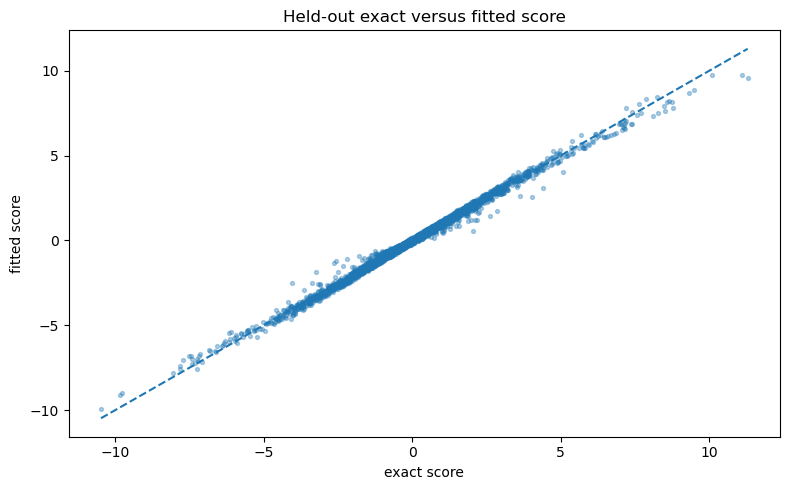

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task7_score_exact_vs_fitted.png


In [11]:
plt.figure(
    figsize=(8, 5)
)

plt.scatter(
    s_test[:4000],
    predicted_test[:4000],
    s=8,
    alpha=0.35,
)

low = min(
    float(
        s_test[:4000].min()
    ),
    float(
        predicted_test[:4000].min()
    ),
)

high = max(
    float(
        s_test[:4000].max()
    ),
    float(
        predicted_test[:4000].max()
    ),
)

plt.plot(
    [low, high],
    [low, high],
    linestyle="--",
)

plt.xlabel("exact score")
plt.ylabel("fitted score")
plt.title(
    "Held-out exact versus fitted score"
)
plt.tight_layout()

path = (
    RESULT_DIR
    / "task7_score_exact_vs_fitted.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

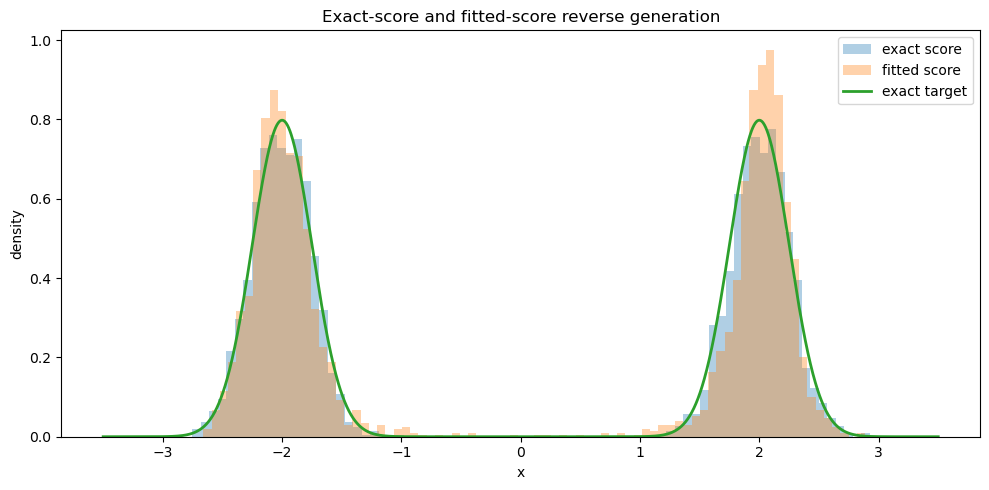

Saved: C:\Users\benja\OneDrive\Univeristy of Alabama courses\Math 638\Project 2\HW8.1\result images\hw8_1\task7_exact_vs_fitted_generation.png


In [12]:
def target_density(x):
    return (
        0.5
        * norm.pdf(
            x,
            loc=-A,
            scale=SIGMA0,
        )
        + 0.5
        * norm.pdf(
            x,
            loc=A,
            scale=SIGMA0,
        )
    )


x_plot = np.linspace(
    -3.5,
    3.5,
    2000,
)

plt.figure(
    figsize=(10, 5)
)

plt.hist(
    exact_generated,
    bins=80,
    density=True,
    alpha=0.35,
    label="exact score",
)

plt.hist(
    fitted_generated,
    bins=80,
    density=True,
    alpha=0.35,
    label="fitted score",
)

plt.plot(
    x_plot,
    target_density(
        x_plot
    ),
    linewidth=2.0,
    label="exact target",
)

plt.xlabel("x")
plt.ylabel("density")
plt.title(
    "Exact-score and fitted-score reverse generation"
)
plt.legend()
plt.tight_layout()

path = (
    RESULT_DIR
    / "task7_exact_vs_fitted_generation.png"
)

plt.savefig(
    path,
    dpi=200,
)

plt.show()

print("Saved:", path.resolve())

# Task 7 Conclusion

The fitted-score model is evaluated on held-out score labels and on reverse generation from exactly the same initial noise used by the exact-score model.

The saved run has held-out score RMSE about $0.1666$. Its generated distribution has good mean, variance, and mode balance, but it is measurably worse than exact-score generation: the fitted-score KS statistic is about $0.0458$ versus $0.0159$ for the exact score, and the paired fitted-versus-exact sample RMSE is about $0.1587$.

Mode balance is reported, but it is not treated as sufficient evidence of score quality. In particular, odd symmetry in $x$ was not imposed, so near-balanced mode mass is an empirical result rather than an architectural guarantee.

The validation MSE was still improving at epoch 60, which is the declared maximum training budget. Therefore this run should be described as a finite-budget fitted approximation, not as evidence that optimization had fully converged.

Task 8 asks an LLM to derive the reverse dynamics and audits the sign of the score term.
